STUDENT DATASET
Student Name  Study Hours  Attendance  Previous Marks  Final Marks Result
        Arun            2          60              45           48   Fail
        Bala            3          65              50           52   Pass
      Charan            5          75              60           65   Pass
       David            1          40              30           35   Fail
       Ezhil            6          85              70           78   Pass
      Ganesh            4          70              55           60   Pass
        Hari            2          50              35           40   Fail
     Karthik            7          90              80           88   Pass
       Manoj            3          55              40           45   Fail
      Naveen            8          95              85           92   Pass
     Praveen            5          80              65           72   Pass
        Ravi            1          35              25           30   Fail

First Five Records:
 

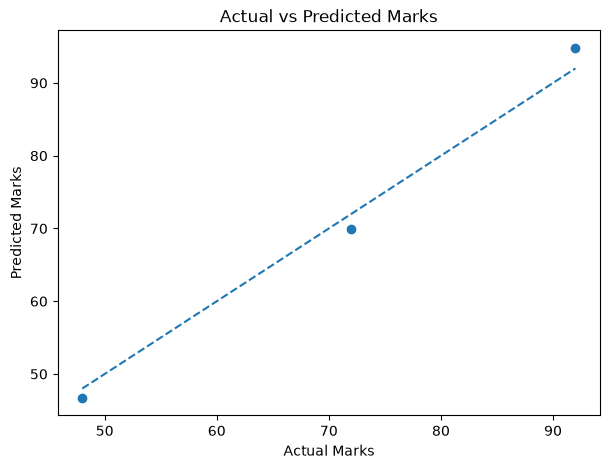

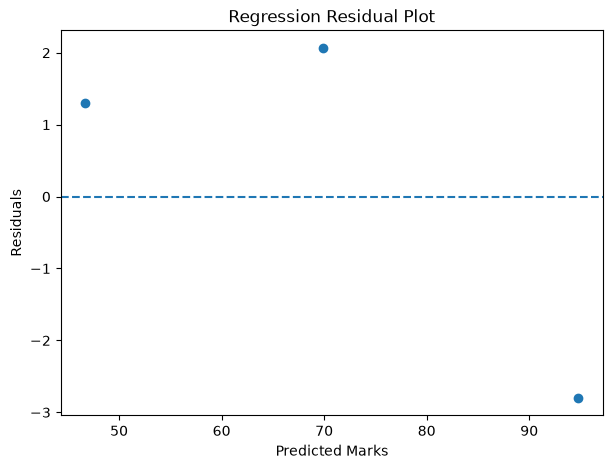


Actual Results:
[0 1 1]

Predicted Results:
['Fail', 'Pass', 'Pass']

CLASSIFICATION EVALUATION
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


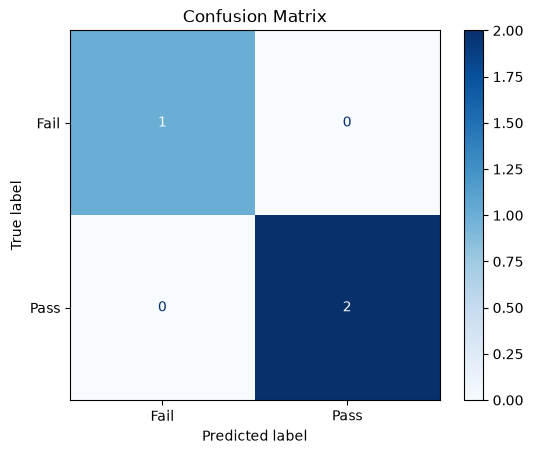


       ENTER STUDENT DETAILS       


Enter Student Name:  hari
Enter Study Hours:  12
Enter Attendance Percentage:  85
Enter Previous Marks:  68



          STUDENT REPORT           
Student Name: hari
Study Hours: 12.0
Attendance: 85.0 %
Previous Marks: 68.0
------------------------------------
Predicted Final Marks: 90.23
Predicted Result: Pass

COMPARISON OF BOTH MODELS
            Comparison         Regression Model                  Classification Model
        Algorithm Used        Linear Regression                   Logistic Regression
       Target Variable              Final Marks                          Pass or Fail
    Type of Prediction     Numerical Prediction                Categorical Prediction
    Evaluation Metrics MAE, MSE, RMSE, R2 Score Accuracy, Precision, Recall, F1 Score
Real-World Application Predicting Student Marks            Predicting Student Results


In [1]:
# COMMON SETUP

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# 2. Create Dataset

data = {
    'Student Name': [
        'Arun', 'Bala', 'Charan', 'David',
        'Ezhil', 'Ganesh', 'Hari', 'Karthik',
        'Manoj', 'Naveen', 'Praveen', 'Ravi'
    ],

    'Study Hours': [2, 3, 5, 1, 6, 4, 2, 7, 3, 8, 5, 1],

    'Attendance': [60, 65, 75, 40, 85, 70, 50, 90, 55, 95, 80, 35],

    'Previous Marks': [45, 50, 60, 30, 70, 55, 35, 80, 40, 85, 65, 25],

    'Final Marks': [48, 52, 65, 35, 78, 60, 40, 88, 45, 92, 72, 30],

    'Result': [
        'Fail', 'Pass', 'Pass', 'Fail', 'Pass', 'Pass',
        'Fail', 'Pass', 'Fail', 'Pass', 'Pass', 'Fail'
    ]
}

df = pd.DataFrame(data)

print("STUDENT DATASET")
print(df.to_string(index=False))


# 3. Inspect Dataset

print("\nFirst Five Records:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

print("\nDataset Shape:")
print(df.shape)


# TASK 1 - REGRESSION MODEL

# 1. Select Input Features

X = df[['Study Hours', 'Attendance', 'Previous Marks']]

# 2. Select Target Variable

y = df['Final Marks']

# 3. Split Data

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# 4. Create Model

reg_model = LinearRegression()

# 5. Train Model

reg_model.fit(X_train_reg, y_train_reg)

# 6. Predict Marks

reg_predictions = reg_model.predict(X_test_reg)

print("\nActual Marks:")
print(y_test_reg.values)

print("\nPredicted Marks:")
print(np.round(reg_predictions, 2))


# 7. Evaluate Regression Model

mae = mean_absolute_error(y_test_reg, reg_predictions)
mse = mean_squared_error(y_test_reg, reg_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, reg_predictions)

print("\nREGRESSION EVALUATION")

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))


# 8. Actual vs Predicted Graph

plt.figure(figsize=(7, 5))

plt.scatter(y_test_reg, reg_predictions)

plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    linestyle='--'
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")

plt.show()


# 9. Residual Plot

residuals = y_test_reg - reg_predictions

plt.figure(figsize=(7, 5))

plt.scatter(reg_predictions, residuals)
plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Marks")
plt.ylabel("Residuals")
plt.title("Regression Residual Plot")

plt.show()


# TASK 2 - CLASSIFICATION MODEL

# 1. Select Input Features

X = df[['Study Hours', 'Attendance', 'Previous Marks']]

# 2. Select Target Variable

y_class = df['Result'].map({'Fail': 0, 'Pass': 1})

# 3. Split Data

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X, y_class, test_size=0.25,
    random_state=42, stratify=y_class
)

# 4. Create Logistic Regression Model

class_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

# 5. Train Model

class_model.fit(X_train_class, y_train_class)

# 6. Predict Results

class_predictions = class_model.predict(X_test_class)

print("\nActual Results:")
print(y_test_class.values)

print("\nPredicted Results:")
print([
    'Pass' if value == 1 else 'Fail'
    for value in class_predictions
])


# 7. Evaluate Classification Model

accuracy = accuracy_score(y_test_class, class_predictions)

precision = precision_score(
    y_test_class, class_predictions, zero_division=0
)

recall = recall_score(
    y_test_class, class_predictions, zero_division=0
)

f1 = f1_score(
    y_test_class, class_predictions, zero_division=0
)

print("\nCLASSIFICATION EVALUATION")

print("Accuracy:", round(accuracy, 2))
print("Precision:", round(precision, 2))
print("Recall:", round(recall, 2))
print("F1 Score:", round(f1, 2))


# 8. Confusion Matrix

cm = confusion_matrix(
    y_test_class, class_predictions, labels=[0, 1]
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail', 'Pass']
)

cm_display.plot(cmap='Blues')

plt.title("Confusion Matrix")

plt.show()


# TASK 3 - INTERACTIVE STUDENT INPUT

print("\n====================================")
print("       ENTER STUDENT DETAILS       ")
print("====================================")

# Get Student Name

student_name = input("Enter Student Name: ")

# Get Study Hours

study_hours = float(input("Enter Study Hours: "))

# Get Attendance

attendance = float(input("Enter Attendance Percentage: "))

# Get Previous Marks

previous_marks = float(input("Enter Previous Marks: "))

# Validate Inputs

if not student_name.strip():
    raise ValueError("Student name cannot be empty.")

if study_hours < 0:
    raise ValueError("Study hours cannot be negative.")

if not 0 <= attendance <= 100:
    raise ValueError("Attendance must be between 0 and 100.")

if not 0 <= previous_marks <= 100:
    raise ValueError("Previous marks must be between 0 and 100.")


# Create New Student Data

new_student = pd.DataFrame({
    'Study Hours': [study_hours],
    'Attendance': [attendance],
    'Previous Marks': [previous_marks]
})


# 1. Predict Final Marks

predicted_marks = reg_model.predict(new_student)

# Keep Marks Within 0-100

predicted_marks = np.clip(predicted_marks, 0, 100)


# 2. Predict Pass or Fail

predicted_result = class_model.predict(new_student)

final_result = "Pass" if predicted_result[0] == 1 else "Fail"


# 3. Display Student Details

print("\n====================================")
print("          STUDENT REPORT           ")
print("====================================")

print("Student Name:", student_name)
print("Study Hours:", study_hours)
print("Attendance:", attendance, "%")
print("Previous Marks:", previous_marks)

print("------------------------------------")

print("Predicted Final Marks:", round(predicted_marks[0], 2))
print("Predicted Result:", final_result)

print("====================================")


# TASK 4 - COMPARISON OF BOTH MODELS

comparison = pd.DataFrame({

    'Comparison': [
        'Algorithm Used',
        'Target Variable',
        'Type of Prediction',
        'Evaluation Metrics',
        'Real-World Application'
    ],

    'Regression Model': [
        'Linear Regression',
        'Final Marks',
        'Numerical Prediction',
        'MAE, MSE, RMSE, R2 Score',
        'Predicting Student Marks'
    ],

    'Classification Model': [
        'Logistic Regression',
        'Pass or Fail',
        'Categorical Prediction',
        'Accuracy, Precision, Recall, F1 Score',
        'Predicting Student Results'
    ]
})

print("\nCOMPARISON OF BOTH MODELS")

print(comparison.to_string(index=False))
